Dataset loaded successfully!
Daily records: 395311
Countries: 194
Saved: images/gdp_vs_vaccination.png


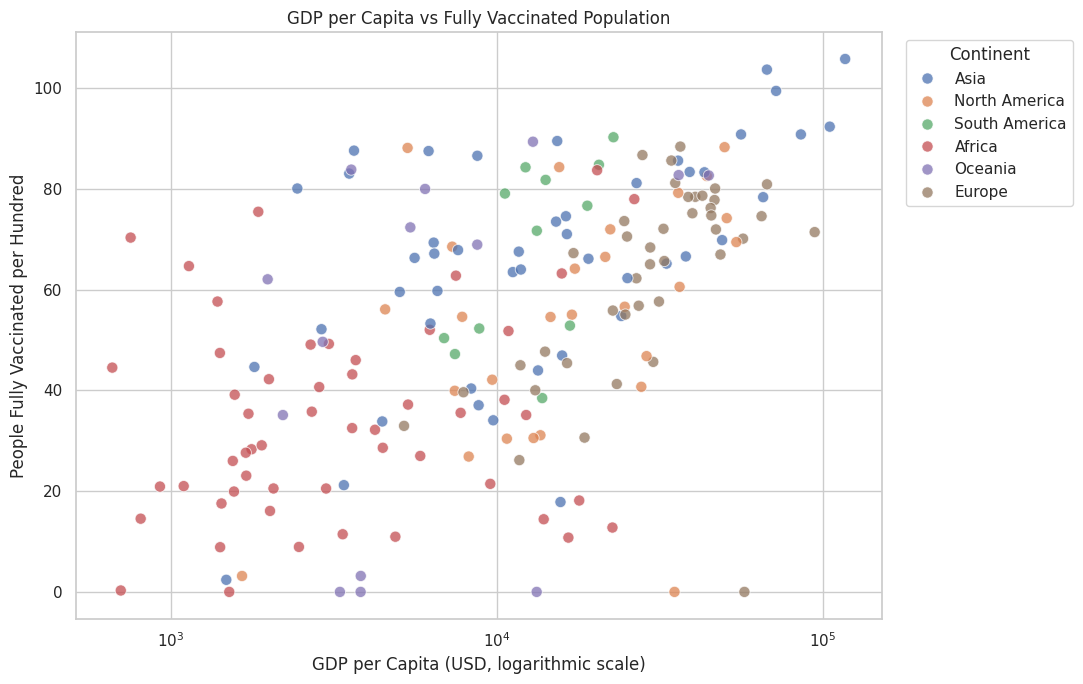

Saved: images/vaccination_timeline.png


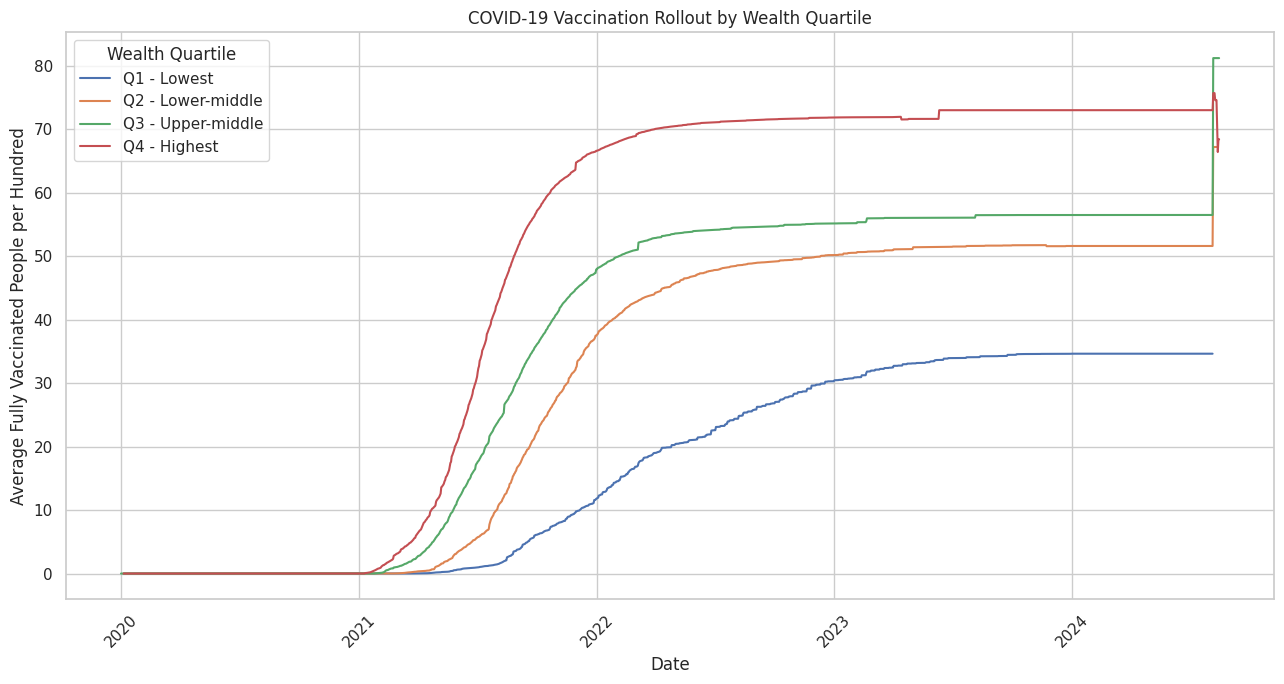

Saved: images/gdp_vs_mortality.png


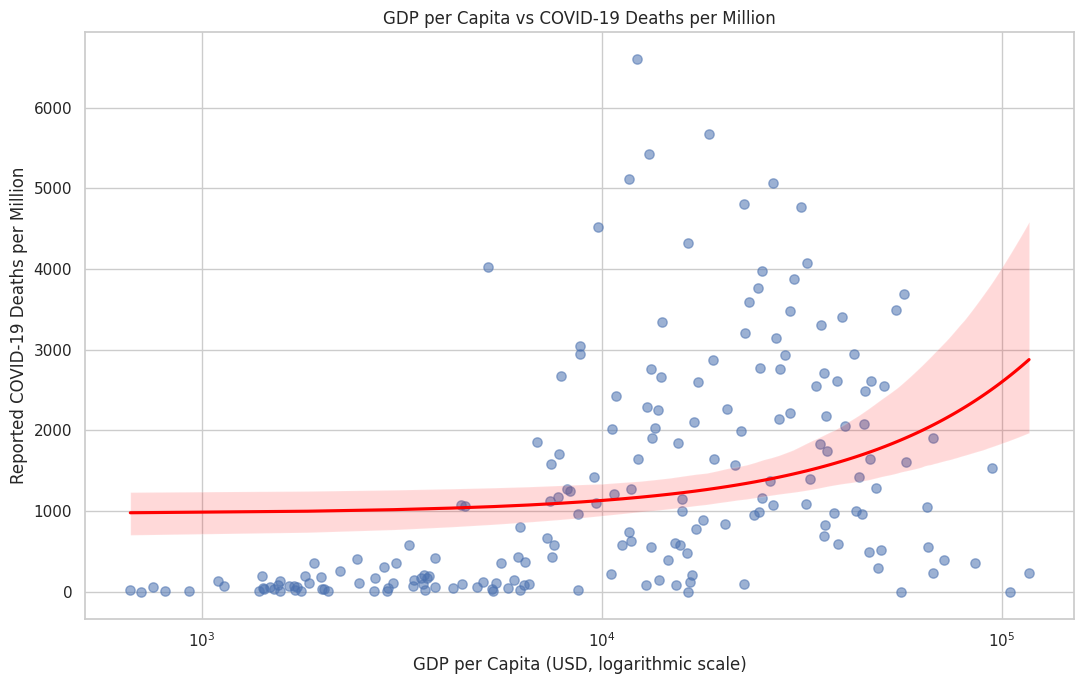

Saved: images/vaccination_by_quartile.png


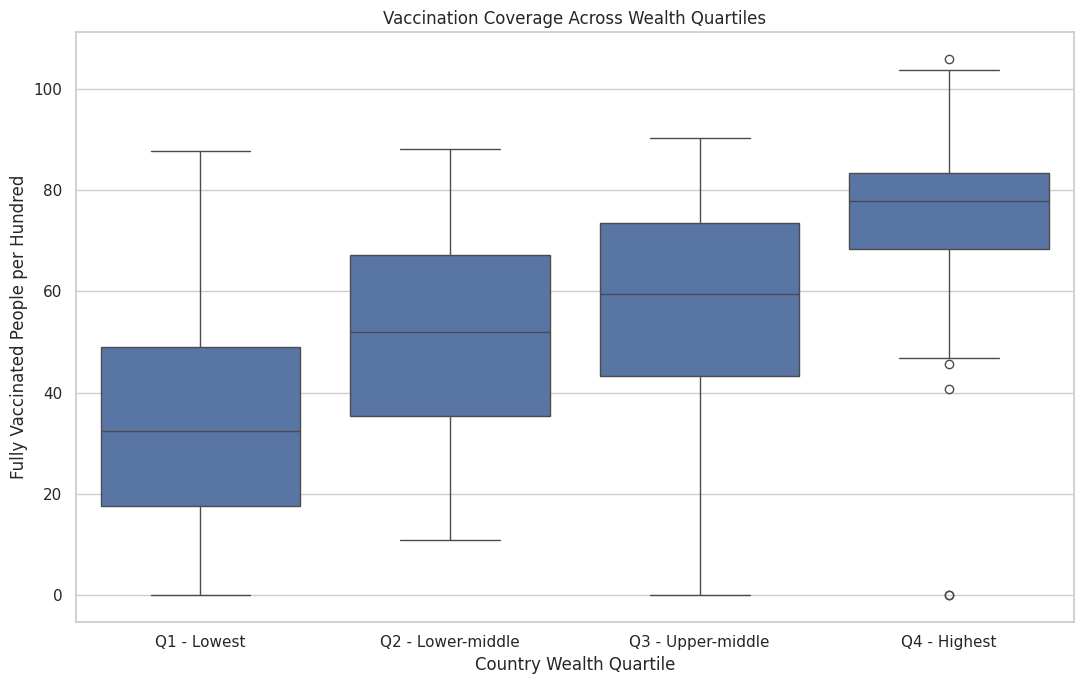

Saved: images/correlation_heatmap.png


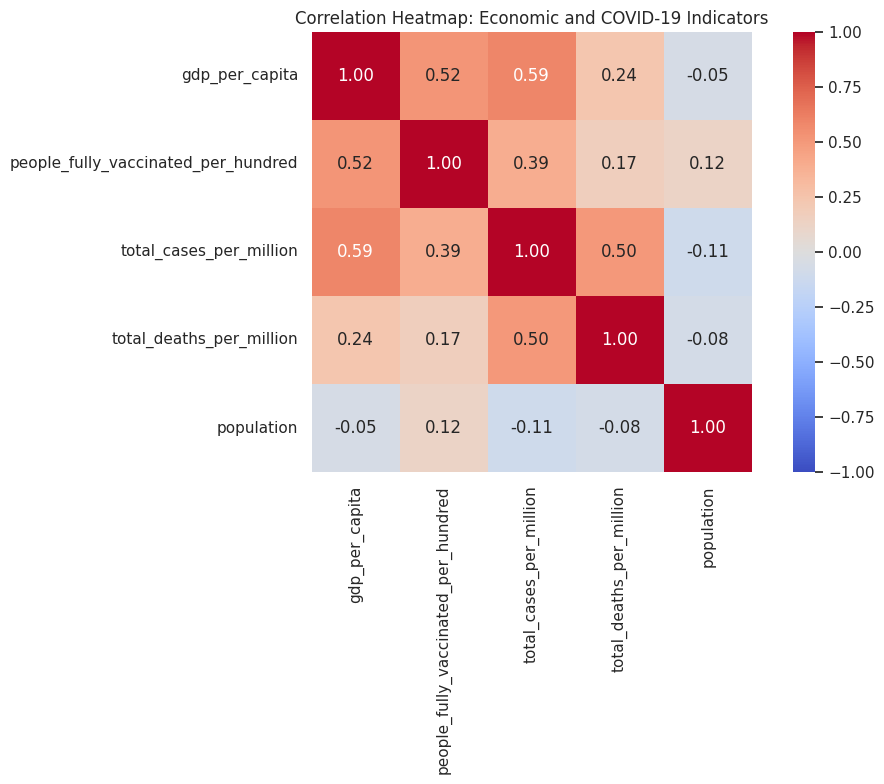


All five graphs have been saved!
Images folder: images/
ZIP file: covid_visualizations.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

# ============================================================
# COLLABORATIVE DATA SCIENCE PROJECT
# Topic: Do Richer Countries Handle COVID-19 Better?
# Member 2: Data Visualization using Matplotlib and Seaborn
# ============================================================

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Google Colab download support
from google.colab import files

# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

df = pd.read_csv("covid_data.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_cols = [
    "gdp_per_capita",
    "people_fully_vaccinated_per_hundred",
    "total_cases_per_million",
    "total_deaths_per_million",
    "population"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep individual countries, excluding aggregate rows
df = df[
    df["iso_code"].astype(str).str.fullmatch(r"[A-Z]{3}", na=False)
].copy()

df = df.dropna(subset=["date", "location"])
df = df.sort_values("date")

# Create an output folder for the graphs
os.makedirs("images", exist_ok=True)

sns.set_theme(style="whitegrid")

# Function to save and display each graph
def save_graph(filename):
    plt.tight_layout()
    plt.savefig(
        f"images/{filename}",
        dpi=300,
        bbox_inches="tight"
    )
    print(f"Saved: images/{filename}")
    plt.show()
    plt.close()


# Get the latest available non-missing value
# for each variable in each country
def latest_values(data, column):
    temp = data.dropna(subset=[column]).sort_values("date")
    return temp.groupby("location").tail(1)[
        ["location", column]
    ]

# One row per country with the latest available values
country_df = (
    df[["location", "iso_code", "continent",
        "gdp_per_capita", "population"]]
    .dropna(subset=["gdp_per_capita"])
    .drop_duplicates(subset=["location"], keep="last")
)

for col in [
    "people_fully_vaccinated_per_hundred",
    "total_cases_per_million",
    "total_deaths_per_million"
]:
    latest = latest_values(df, col)
    country_df = country_df.drop(columns=[col], errors="ignore")
    country_df = country_df.merge(latest, on="location", how="left")

# Assign countries to four wealth quartiles
country_df = country_df.dropna(subset=["gdp_per_capita"])

country_df["wealth_quartile"] = pd.qcut(
    country_df["gdp_per_capita"].rank(method="first"),
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2 - Lower-middle",
        "Q3 - Upper-middle",
        "Q4 - Highest"
    ]
)

print("Dataset loaded successfully!")
print("Daily records:", len(df))
print("Countries:", country_df["location"].nunique())


# ------------------------------------------------------------
# GRAPH 1: GDP PER CAPITA VS VACCINATION RATE
# ------------------------------------------------------------

plot_df = country_df.dropna(
    subset=[
        "gdp_per_capita",
        "people_fully_vaccinated_per_hundred"
    ]
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_df,
    x="gdp_per_capita",
    y="people_fully_vaccinated_per_hundred",
    hue="continent",
    alpha=0.75,
    s=65
)

plt.xscale("log")
plt.title("GDP per Capita vs Fully Vaccinated Population")
plt.xlabel("GDP per Capita (USD, logarithmic scale)")
plt.ylabel("People Fully Vaccinated per Hundred")
plt.legend(title="Continent", bbox_to_anchor=(1.02, 1),
           loc="upper left")

save_graph("gdp_vs_vaccination.png")


# ------------------------------------------------------------
# GRAPH 2: VACCINATION ROLLOUT BY WEALTH QUARTILE
# ------------------------------------------------------------

wealth_map = country_df[
    ["location", "wealth_quartile"]
].copy()

timeline = df.merge(
    wealth_map,
    on="location",
    how="inner"
)

timeline = timeline.dropna(
    subset=["date", "people_fully_vaccinated_per_hundred"]
)

# Average country-level vaccination coverage by date and quartile
timeline_summary = timeline.groupby(
    ["date", "wealth_quartile"],
    observed=True
)["people_fully_vaccinated_per_hundred"].mean().reset_index()

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=timeline_summary,
    x="date",
    y="people_fully_vaccinated_per_hundred",
    hue="wealth_quartile"
)

plt.title("COVID-19 Vaccination Rollout by Wealth Quartile")
plt.xlabel("Date")
plt.ylabel("Average Fully Vaccinated People per Hundred")
plt.legend(title="Wealth Quartile")
plt.xticks(rotation=45)

save_graph("vaccination_timeline.png")


# ------------------------------------------------------------
# GRAPH 3: GDP PER CAPITA VS COVID-19 DEATHS PER MILLION
# ------------------------------------------------------------

plot_df = country_df.dropna(
    subset=["gdp_per_capita", "total_deaths_per_million"]
)

plt.figure(figsize=(11, 7))

sns.regplot(
    data=plot_df,
    x="gdp_per_capita",
    y="total_deaths_per_million",
    scatter_kws={"alpha": 0.55, "s": 45},
    line_kws={"color": "red"}
)

plt.xscale("log")
plt.title("GDP per Capita vs COVID-19 Deaths per Million")
plt.xlabel("GDP per Capita (USD, logarithmic scale)")
plt.ylabel("Reported COVID-19 Deaths per Million")

save_graph("gdp_vs_mortality.png")


# ------------------------------------------------------------
# GRAPH 4: VACCINATION COVERAGE BY WEALTH QUARTILE
# ------------------------------------------------------------

plot_df = country_df.dropna(
    subset=[
        "wealth_quartile",
        "people_fully_vaccinated_per_hundred"
    ]
)

plt.figure(figsize=(11, 7))

sns.boxplot(
    data=plot_df,
    x="wealth_quartile",
    y="people_fully_vaccinated_per_hundred"
)

plt.title("Vaccination Coverage Across Wealth Quartiles")
plt.xlabel("Country Wealth Quartile")
plt.ylabel("Fully Vaccinated People per Hundred")

save_graph("vaccination_by_quartile.png")


# ------------------------------------------------------------
# GRAPH 5: CORRELATION HEATMAP
# ------------------------------------------------------------

corr_columns = [
    "gdp_per_capita",
    "people_fully_vaccinated_per_hundred",
    "total_cases_per_million",
    "total_deaths_per_million",
    "population"
]

corr = country_df[corr_columns].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Heatmap: Economic and COVID-19 Indicators")

save_graph("correlation_heatmap.png")


# ------------------------------------------------------------
# 6. CREATE A ZIP FILE CONTAINING ALL FIVE GRAPHS
# ------------------------------------------------------------

zip_name = "covid_visualizations.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir("images"):
        if filename.endswith(".png"):
            zipf.write(
                os.path.join("images", filename),
                arcname=f"images/{filename}"
            )

print("\nAll five graphs have been saved!")
print("Images folder: images/")
print("ZIP file:", zip_name)

# Download all five graphs together
files.download(zip_name)
